<a href="https://colab.research.google.com/github/egomez-DA/Proyecto-Final-RappiPlus-De-datos-a-decisiones-de-negocio/blob/main/S12_Estudiante_Proyecto_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyecto RappiPlus: de datos a decisiones de negocio

**Introducción**


El objetivo de este proyecto es evaluar el desempeño del servicio **RappiPlus** para apoyar **decisiones de negocio basadas en datos**.

Se trabajan con múltiples datasets del negocio:

- **rappiplus_orders_raw.csv** → información de pedidos, precios, descuentos y revenue  
- **rappiplus_catalog.csv** → costos de productos, categorías y proveedores  
- **rappiplus_marketing_spend.csv** → inversión en marketing por canal y país  
- **events / users / user_activity (SQL)** → comportamiento del usuario dentro de la plataforma  
- **experiment_checkout_ui.csv** → resultados de un experimento A/B en el checkout  

El análisis sigue una lógica clara y progresiva:

1. 🔍 Evaluar si podemos confiar en los datos (calidad de datos en Python)

2. 💰 Analizar si el negocio es rentable (revenue, costos y profit)  

3. 🛒 Entender dónde se pierden los usuarios (funnel de conversión)  

4. 🔁 Evaluar si los usuarios regresan (retención por cohortes)  

5. 🧪 Validar si los cambios generan impacto (test estadístico)  

6. 📊 Comunicar los resultados (dashboard en BI)  

A lo largo del proyecto, se transforman datos en insights para responder preguntas clave del negocio y proponer **recomendaciones accionables**.

---

## 🔹 Paso 1: Cargar y validar la calidad de los datos

---

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:** Familiarizarte con la estructura de los datasets del negocio antes de analizarlos.

**Instrucciones:**

- Importa las librerías necesarias
- Carga los archivos:
  - `rappiplus_orders_raw.csv`
  - `rappiplus_catalog.csv`
  - `rappiplus_marketing_spend.csv`
- Guarda los DataFrames en:
  - `orders`, `catalog`, `marketing`
- Explora cada dataset.

---

In [ ]:
# importar librerías
import pandas as pd
import numpy as np

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from scipy.stats import levene
from scipy.stats import ttest_ind
from statsmodels.stats.proportion import proportions_ztest
from scipy.stats import pointbiserialr, chi2_contingency

In [ ]:
# cargar archivos
orders = pd.read_csv('https://practicum-content.s3.amazonaws.com/datasets/rappiplus_orders_raw.csv')
catalog = pd.read_csv('https://practicum-content.s3.amazonaws.com/datasets/rappiplus_catalog.csv')
marketing =pd.read_csv('https://practicum-content.s3.amazonaws.com/datasets/rappiplus_marketing_spend.csv')

In [ ]:
# explorar datasets orders
orders.info()
orders.head(5)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25100 entries, 0 to 25099
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id_pedido           25100 non-null  object 
 1   id_usuario          25100 non-null  object 
 2   fecha_hora_pedido   25100 non-null  object 
 3   pais                24800 non-null  object 
 4   dispositivo         25080 non-null  object 
 5   fuente_referencia   25070 non-null  object 
 6   nombre_producto     25070 non-null  object 
 7   categoria_producto  25020 non-null  object 
 8   cantidad            25050 non-null  float64
 9   precio_unitario     25050 non-null  float64
 10  monto_descuento     25050 non-null  float64
 11  monto_total         25100 non-null  float64
dtypes: float64(4), object(8)
memory usage: 2.3+ MB


,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total
0,order_0,user_6993,2025-05-22,Argentina,desktop,organic,Jacket-Winter-M,Moda,2.0,332.69,0.0,665.37
1,order_1,user_1329,2025-06-15,Mexico,desktop,paid_search,Tablet-Standard-64GB,Electronica,1.0,176.86,5.0,171.86
2,order_2,user_3194,2025-05-02,Argentina,desktop,social,Blender-XL-Red,Hogar,2.0,102.99,10.0,195.99
3,order_3,user_4510,2025-06-09,Colombia,mobile,social,Tablet-Standard-64GB,Electronica,1.0,257.87,15.0,242.87
4,order_4,user_5044,2025-03-30,Argentina,desktop,paid_search,Blender-XL-Red,Hogar,1.0,336.28,0.0,336.28


OBSERVACIONES:
Dataset orders:  
- fecha_hora_pedido convertir a fecha.
- pais 24800 non-null de 25100

In [ ]:
# explorar datasets catalog
catalog.info()
catalog.head(5)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7 entries, 0 to 6
Data columns (total 4 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   nombre_producto     7 non-null      object 
 1   categoria_producto  7 non-null      object 
 2   costo_unitario      7 non-null      float64
 3   proveedor           7 non-null      object 
dtypes: float64(1), object(3)
memory usage: 352.0+ bytes


,nombre_producto,categoria_producto,costo_unitario,proveedor
0,Laptop-Gaming-16GB,Electrónica,280.68,"Fuller, Pena and Myers"
1,Phone-Pro-128GB,Electrónica,10.12,King Ltd
2,Tablet-Standard-64GB,Electrónica,25.21,Bowers LLC
3,Blender-XL-Red,Hogar,176.64,Long-Reid
4,Vacuum-Pro-Black,Hogar,16.60,"Rivera, Carr and Finley"


Observaciones -Dataset catalog:
- Datos completos.OK

In [ ]:
# explorar datasets marketing
marketing.info()
marketing.head(5)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1620 entries, 0 to 1619
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   fecha       1620 non-null   object 
 1   pais        1620 non-null   object 
 2   id_campaña  1620 non-null   object 
 3   canal       1519 non-null   object 
 4   gasto       1620 non-null   float64
dtypes: float64(1), object(4)
memory usage: 63.4+ KB


,fecha,pais,id_campaña,canal,gasto
0,2025-01-01,Mexico,organic_Mexico,organic,2446.25
1,2025-01-01,Mexico,paid_search_Mexico,paid_search,2704.34
2,2025-01-01,Mexico,social_Mexico,social,2045.01
3,2025-01-01,Colombia,organic_Colombia,organic,2597.21
4,2025-01-01,Colombia,paid_search_Colombia,paid_search,1771.40


Observaciones- Dataset marketing:
- fecha convertir type.
- canal tiene 1519 datos de 1620


---

### Revisión y calidad de datos

**🎯 Objetivo:** Detectar y corregir problemas en los datos que puedan afectar el análisis de revenue, costos y rentabilidad.

Se revisan los 3 datasets
- Validar y convertir fechas al formato correcto  
- Revisar variables numéricas (sin negativos o ceros inválidos)  
- Verificar consistencia de montos  
- Eliminar duplicados  
- Revisar variables categóricas
---

In [ ]:
# Validar y convertir fechas al formato correcto
orders['fecha_hora_pedido']= pd.to_datetime(orders['fecha_hora_pedido'], errors='coerce', utc=True).dt.tz_localize(None)
print(orders['fecha_hora_pedido'].dtype)

datetime64[ns]


In [ ]:
marketing['fecha']=pd.to_datetime(marketing['fecha'], errors='coerce', utc= True).dt.tz_localize(None)
print(marketing['fecha'].dtype)

datetime64[ns]


In [ ]:
# estandazizar 'Electronica'
orders['categoria_producto']= orders['categoria_producto'].replace('Electronica', 'Electrónica')
orders['categoria_producto'].unique()

array(['Moda', 'Electrónica', 'Hogar', nan], dtype=object)

In [ ]:
# extraer nombre de columnas numericas
orders.columns

Index(['id_pedido', 'id_usuario', 'fecha_hora_pedido', 'pais', 'dispositivo',
       'fuente_referencia', 'nombre_producto', 'categoria_producto',
       'cantidad', 'precio_unitario', 'monto_descuento', 'monto_total'],
      dtype='object')

In [ ]:
#Revisar variables numéricas (sin negativos o ceros inválidos)
orders_numericas= ['cantidad', 'precio_unitario', 'monto_descuento', 'monto_total']

for cols in orders_numericas:
    print(cols, 'nulos', orders[cols].isna().sum())
    print(cols, 'valores cero', (orders[cols]==0).sum())
    print(cols, 'valores negativos', (orders[cols]<0).sum())
    print('-'*50)

cantidad nulos 50
cantidad valores cero 0
cantidad valores negativos 4
--------------------------------------------------
precio_unitario nulos 50
precio_unitario valores cero 0
precio_unitario valores negativos 0
--------------------------------------------------
monto_descuento nulos 50
monto_descuento valores cero 12551
monto_descuento valores negativos 0
--------------------------------------------------
monto_total nulos 0
monto_total valores cero 0
monto_total valores negativos 4
--------------------------------------------------


In [ ]:
# si tengo valores de 'precio_unitario' y 'monto_total' puedo calcular 'cantidad'
cantidad_calculada = orders['monto_total'] / orders['precio_unitario']
orders['cantidad'] = orders['cantidad'].fillna(cantidad_calculada)

orders['cantidad'].isna().sum()

50

In [ ]:
# se comprueba que no se puede realizar el calculo porque las otras variables son NaN
filas_problema = orders[orders['cantidad'].isna()]
print(filas_problema[['cantidad', 'precio_unitario', 'monto_descuento', 'monto_total']])

     cantidad  precio_unitario  monto_descuento  monto_total
74        NaN              NaN              NaN       595.85
75        NaN              NaN              NaN       458.15
76        NaN              NaN              NaN       319.75
77        NaN              NaN              NaN       227.55
78        NaN              NaN              NaN       432.39
79        NaN              NaN              NaN       527.15
80        NaN              NaN              NaN       711.18
81        NaN              NaN              NaN        41.08
82        NaN              NaN              NaN       431.55
83        NaN              NaN              NaN       279.35
84        NaN              NaN              NaN       785.89
85        NaN              NaN              NaN       576.13
86        NaN              NaN              NaN        49.80
87        NaN              NaN              NaN       143.11
88        NaN              NaN              NaN       856.06
89        NaN           

In [ ]:
# se sustituye NaN por cero:
cols_nulas=['cantidad', 'precio_unitario']

for col in cols_nulas:
    orders[col] = orders[col].fillna(0)
    print(col, 'nulos:', orders[col].isna().sum())

cantidad nulos: 0
precio_unitario nulos: 0


In [ ]:
# se sustituye NaN por mediana:
mediana= orders['monto_descuento'].median()
orders['monto_descuento'] = orders['monto_descuento'].fillna(mediana)
orders['monto_descuento'].isna().sum()

0

In [ ]:
# como solo son 4 valores negativos, se eliminaran para no dispersar las estadisticas
print("Filas antes:", orders.shape[0])
orders = orders[orders['cantidad'] >= 0]
print("Filas después:", orders.shape[0])


Filas antes: 25100
Filas después: 25096


In [ ]:
# convertir cantidad a entero
orders['cantidad'] = orders['cantidad'].astype(int)
orders['cantidad'].dtype

dtype('int64')

In [ ]:
# Verificar consistencia de montos
for cols in orders_numericas:
    print(f"{cols}\n{orders[cols].describe()}\n")

cantidad
count    25096.000000
mean         7.079933
std        296.005485
min          0.000000
25%          1.000000
50%          2.000000
75%          2.000000
max      20000.000000
Name: cantidad, dtype: float64

precio_unitario
count    25096.000000
mean       258.787775
std        139.058501
min          0.000000
25%        137.600000
50%        258.150000
75%        380.075000
max        499.960000
Name: precio_unitario, dtype: float64

monto_descuento
count    25096.000000
mean         4.491752
std          5.221884
min          0.000000
25%          0.000000
50%          0.000000
75%         10.000000
max         15.000000
Name: monto_descuento, dtype: float64

monto_total
count    2.509600e+04
mean     2.073056e+03
std      9.895783e+04
min      5.240000e+00
25%      1.805925e+02
50%      3.418050e+02
75%      5.185950e+02
max      8.840200e+06
Name: monto_total, dtype: float64



In [ ]:
#Revisar variables numéricas (sin negativos o ceros inválidos)
(catalog['costo_unitario']<=0).sum()

0

In [ ]:
# Verificar consistencia de montos
catalog['costo_unitario'].describe()

count      7.000000
mean     102.252857
std      111.011563
min       10.120000
25%       16.905000
50%       25.210000
75%      182.975000
max      280.680000
Name: costo_unitario, dtype: float64

In [ ]:
#Revisar variables numéricas (sin negativos o ceros inválidos)
(marketing['gasto']<=0).sum()

0

In [ ]:
# Verificar consistencia de montos
marketing['gasto'].describe()

count    1620.00000
mean     1772.74292
std       734.43294
min       501.11000
25%      1128.03000
50%      1782.42500
75%      2420.68500
max      2999.36000
Name: gasto, dtype: float64

In [ ]:
# Eliminar duplicados
print(orders.duplicated().sum())

100


In [ ]:
# Eliminar duplicados
print("Filas antes:", orders.shape[0])
orders = orders.drop_duplicates(keep='first')
print("Filas después:", orders.shape[0])

Filas antes: 25096
Filas después: 24996


In [ ]:
print(orders.duplicated(subset=['id_pedido']).sum())

0


In [ ]:
# Eliminar duplicados
print(catalog.duplicated().sum())

0


In [ ]:
# Eliminar duplicados
print(marketing.duplicated().sum())

0


In [ ]:
#Corroborar variables numéricas sin negativos o ceros inválidos
for cols in orders_numericas:
    print(cols, 'nulos', orders[cols].isna().sum())
    print(cols, 'valores cero', (orders[cols]==0).sum())
    print(cols, 'valores negativos', (orders[cols]<0).sum())
    print('-'*50)

cantidad nulos 0
cantidad valores cero 50
cantidad valores negativos 0
--------------------------------------------------
precio_unitario nulos 0
precio_unitario valores cero 50
precio_unitario valores negativos 0
--------------------------------------------------
monto_descuento nulos 0
monto_descuento valores cero 12547
monto_descuento valores negativos 0
--------------------------------------------------
monto_total nulos 0
monto_total valores cero 0
monto_total valores negativos 0
--------------------------------------------------


In [ ]:
# Revisar variables categóricas


cols_categoricas_orders= ['id_pedido', 'id_usuario', 'fecha_hora_pedido', 'pais', 'dispositivo', 'fuente_referencia', 'nombre_producto', 'categoria_producto']

for col in cols_categoricas_orders:
    print('-'*50)
    print(col)
    print(orders[col].unique())



--------------------------------------------------
id_pedido
['order_0' 'order_1' 'order_2' ... 'order_24997' 'order_24998'
 'order_24999']
--------------------------------------------------
id_usuario
['user_6993' 'user_1329' 'user_3194' ... 'user_7965' 'user_76' 'user_670']
--------------------------------------------------
fecha_hora_pedido
['2025-05-22T00:00:00.000000000' '2025-06-15T00:00:00.000000000'
 '2025-05-02T00:00:00.000000000' '2025-06-09T00:00:00.000000000'
 '2025-03-30T00:00:00.000000000' '2025-04-22T00:00:00.000000000'
 '2025-03-15T00:00:00.000000000' '2025-05-01T00:00:00.000000000'
 '2025-03-01T00:00:00.000000000' '2025-05-31T00:00:00.000000000'
 '2025-03-28T00:00:00.000000000' '2025-06-18T00:00:00.000000000'
 '2025-03-17T00:00:00.000000000' '2025-04-10T00:00:00.000000000'
 '2025-06-22T00:00:00.000000000' '2025-04-03T00:00:00.000000000'
 '2025-02-11T00:00:00.000000000' '2025-03-14T00:00:00.000000000'
 '2025-01-23T00:00:00.000000000' '2025-02-03T00:00:00.000000000'
 '20

In [ ]:
# Estandarizar pais: ['Argentina' 'Mexico' 'Colombia' 'mexico' 'colombia' 'argentina' nan]:
orders['pais'] = orders['pais'].str.strip().str.capitalize()

print(orders['pais'].unique())

['Argentina' 'Mexico' 'Colombia' nan]


In [ ]:
# contar NaN:
cols_categoricas= ['pais', 'dispositivo', 'fuente_referencia', 'nombre_producto', 'categoria_producto']

for col in cols_categoricas:
    print('-'*20)
    print(f"{col}\n nulos {orders[col].isna().sum()}")

--------------------
pais
 nulos 296
--------------------
dispositivo
 nulos 20
--------------------
fuente_referencia
 nulos 30
--------------------
nombre_producto
 nulos 30
--------------------
categoria_producto
 nulos 80


In [ ]:
# Quitar NaN:
orders['pais']=orders['pais'].fillna('desconocido')
orders['categoria_producto']=orders['categoria_producto'].fillna('desconocido')

In [ ]:
# se eliminaran para no dispersar las estadisticas
cols_categoricas=['dispositivo', 'fuente_referencia', 'nombre_producto']

print("Filas antes:", orders.shape[0])
orders = orders.dropna(subset=cols_categoricas)
print("Filas después:", orders.shape[0])


Filas antes: 24996
Filas después: 24946


In [ ]:
# Revisar variables categóricas
for col in cols_categoricas_orders:
    print('-'*50)
    print(col)
    print(orders[col].describe())

--------------------------------------------------
id_pedido
count           24946
unique          24946
top       order_15232
freq                1
Name: id_pedido, dtype: object
--------------------------------------------------
id_usuario
count         24946
unique         7640
top       user_7769
freq             11
Name: id_usuario, dtype: object
--------------------------------------------------
fecha_hora_pedido
count                   24946
unique                    181
top       2025-06-25 00:00:00
freq                      175
first     2025-01-01 00:00:00
last      2025-06-30 00:00:00
Name: fecha_hora_pedido, dtype: object
--------------------------------------------------
pais
count      24946
unique         4
top       Mexico
freq        8319
Name: pais, dtype: object
--------------------------------------------------
dispositivo
count       24946
unique          2
top       desktop
freq        12692
Name: dispositivo, dtype: object
----------------------------------------

In [ ]:
# dataset catalog sin nulos, OK.
cols_categoricas_catalog= ['nombre_producto', 'categoria_producto', 'proveedor']

for col in cols_categoricas_catalog:
    print('-'*50)
    print(col)
    print(catalog[col].describe())

--------------------------------------------------
nombre_producto
count                   7
unique                  7
top       Jacket-Winter-M
freq                    1
Name: nombre_producto, dtype: object
--------------------------------------------------
categoria_producto
count               7
unique              3
top       Electrónica
freq                3
Name: categoria_producto, dtype: object
--------------------------------------------------
proveedor
count                          7
unique                         7
top       Fuller, Pena and Myers
freq                           1
Name: proveedor, dtype: object


In [ ]:
cols_categoricas_marketing= ['fecha', 'pais', 'id_campaña', 'canal']

for col in cols_categoricas_marketing:
    print('-'*50)
    print(col)
    print(marketing[col].unique())

--------------------------------------------------
fecha
['2025-01-01T00:00:00.000000000' '2025-01-02T00:00:00.000000000'
 '2025-01-03T00:00:00.000000000' '2025-01-04T00:00:00.000000000'
 '2025-01-05T00:00:00.000000000' '2025-01-06T00:00:00.000000000'
 '2025-01-07T00:00:00.000000000' '2025-01-08T00:00:00.000000000'
 '2025-01-09T00:00:00.000000000' '2025-01-10T00:00:00.000000000'
 '2025-01-11T00:00:00.000000000' '2025-01-12T00:00:00.000000000'
 '2025-01-13T00:00:00.000000000' '2025-01-14T00:00:00.000000000'
 '2025-01-15T00:00:00.000000000' '2025-01-16T00:00:00.000000000'
 '2025-01-17T00:00:00.000000000' '2025-01-18T00:00:00.000000000'
 '2025-01-19T00:00:00.000000000' '2025-01-20T00:00:00.000000000'
 '2025-01-21T00:00:00.000000000' '2025-01-22T00:00:00.000000000'
 '2025-01-23T00:00:00.000000000' '2025-01-24T00:00:00.000000000'
 '2025-01-25T00:00:00.000000000' '2025-01-26T00:00:00.000000000'
 '2025-01-27T00:00:00.000000000' '2025-01-28T00:00:00.000000000'
 '2025-01-29T00:00:00.000000000' 

In [ ]:
for col in cols_categoricas_marketing:
    print('-'*20)
    print(f"{col}\n nulos {marketing[col].isna().sum()}")

--------------------
fecha
 nulos 0
--------------------
pais
 nulos 0
--------------------
id_campaña
 nulos 0
--------------------
canal
 nulos 101


In [ ]:
# Quitar NaN:
marketing['canal']=marketing['canal'].fillna('desconocido')

In [ ]:
for col in cols_categoricas_marketing:
    print('-'*50)
    print(col)
    print(marketing[col].describe())

--------------------------------------------------
fecha
count                    1620
unique                    180
top       2025-06-25 00:00:00
freq                        9
first     2025-01-01 00:00:00
last      2025-06-29 00:00:00
Name: fecha, dtype: object
--------------------------------------------------
pais
count         1620
unique           3
top       Colombia
freq           540
Name: pais, dtype: object
--------------------------------------------------
id_campaña
count                   1620
unique                     9
top       paid_search_Mexico
freq                     180
Name: id_campaña, dtype: object
--------------------------------------------------
canal
count            1620
unique              4
top       paid_search
freq              507
Name: canal, dtype: object


,sum,mean,median,count
pais,,,,
Argentina,20727787.37,2577.121394,342.230,8043
Colombia,11372815.64,1372.202659,340.705,8288
Mexico,19757400.13,2374.972969,342.620,8319
desconocido,111988.05,378.338007,345.405,296


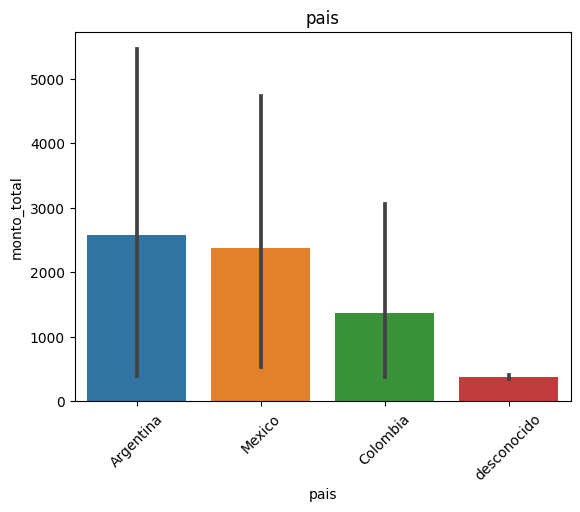

,sum,mean,median,count
dispositivo,,,,
desktop,20165003.56,1588.796373,342.820,12692
mobile,31804987.63,2595.478018,340.905,12254


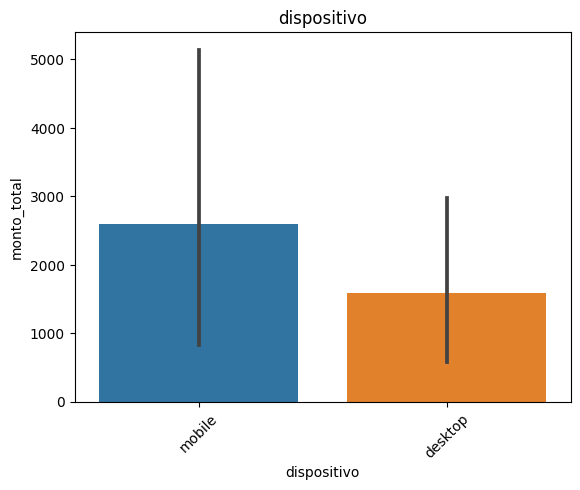

,sum,mean,median,count
fuente_referencia,,,,
organic,12507766.54,1510.052703,336.710,8283
paid_search,25232156.27,3050.309027,347.755,8272
social,14230068.38,1695.872766,341.830,8391


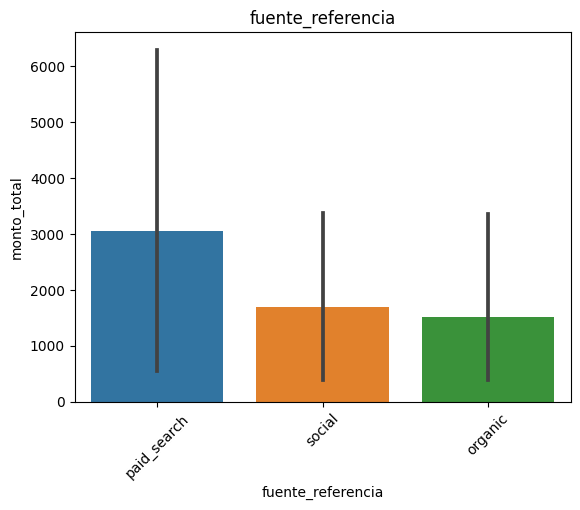

,sum,mean,median,count
nombre_producto,,,,
Blender-XL-Red,1612272.50,386.080580,339.355,4176
Jacket-Winter-M,1610718.48,385.800834,338.530,4175
Laptop-Gaming-16GB,43430855.08,15616.992118,349.390,2781
Phone-Pro-128GB,1056684.70,386.780637,345.850,2732
Sneakers-Urban-42,1573371.48,379.766227,336.320,4143
Tablet-Standard-64GB,1063566.49,384.375313,337.210,2767
Vacuum-Pro-Black,1622522.46,388.907589,346.425,4172


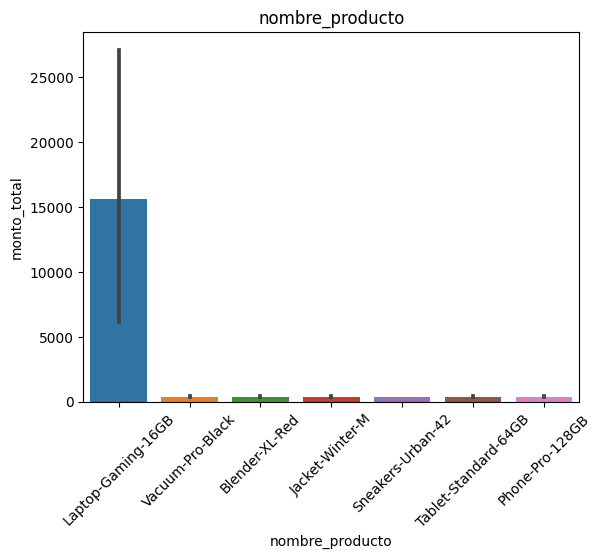

,sum,mean,median,count
categoria_producto,,,,
Electrónica,45547257.61,5508.860379,344.36,8268
Hogar,3229850.53,387.318687,342.62,8339
Moda,3171255.05,382.585963,336.94,8289
desconocido,21628.00,432.560000,437.11,50


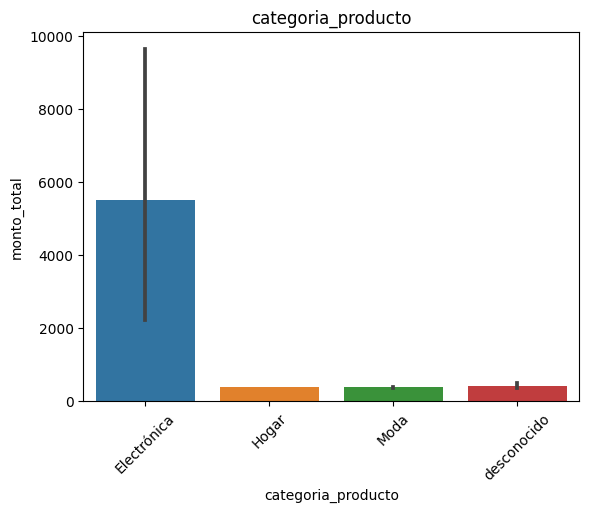

In [ ]:
# Visualizacion relacion con variables categoricas
cols_relacion = ['pais', 'dispositivo', 'fuente_referencia', 'nombre_producto', 'categoria_producto']

for col in cols_relacion:
    data = orders.groupby(col)['monto_total'].agg(['sum', 'mean', 'median', 'count'])
    display(data)

    # Orden descendente según la suma de monto_total
    orden_descendente = data.sort_values('sum', ascending=False).index

    sns.barplot(data=orders, x=col, y='monto_total', order=orden_descendente)
    plt.title(col)
    plt.xticks(rotation=45)
    plt.show()
    plt.close()

,sum,mean,median,count
pais,,,,
Argentina,947694.60,1754.990000,1736.030,540
Colombia,935653.42,1732.691519,1767.920,540
Mexico,988495.51,1830.547241,1848.205,540


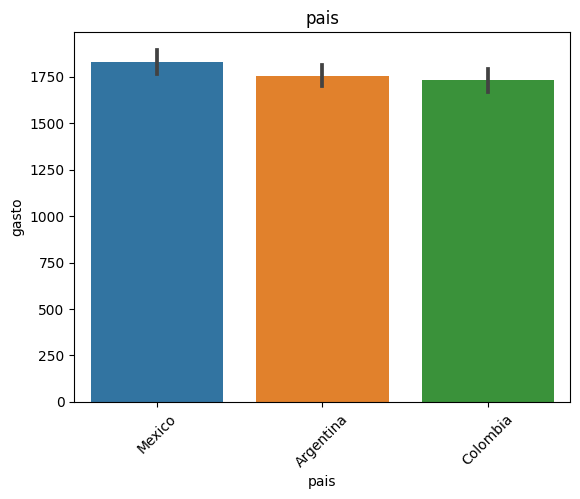

,sum,mean,median,count
canal,,,,
desconocido,177179.10,1754.248515,1719.740,101
organic,913533.01,1805.401206,1823.635,506
paid_search,863088.21,1702.343609,1668.750,507
social,918043.21,1814.314644,1847.605,506


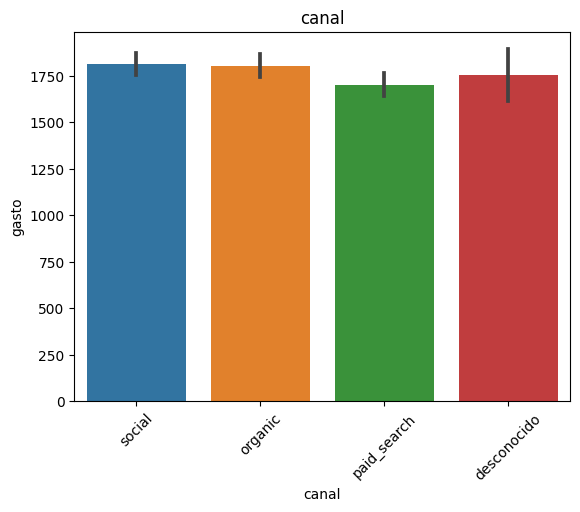

In [ ]:
#Relacion con variables categoricas en dataset marketing
cols_relacion = ['pais', 'canal']

for col in cols_relacion:
    data = marketing.groupby(col)['gasto'].agg(['sum', 'mean', 'median', 'count'])
    display(data)

    # Orden descendente según la suma de monto_total
    orden_descendente = data.sort_values('sum', ascending=False).index

    sns.barplot(data=marketing, x=col, y='gasto', order=orden_descendente)
    plt.title(col)
    plt.xticks(rotation=45)
    plt.show()
    plt.close()

---
**📦 Exportación**: Una vez finalizada la limpieza, se exportan los datasets para utilizarlos en la última etapa del proyecto.

In [ ]:
# exportar datasets
orders.to_csv('orders_clean.csv', index=False)
catalog.to_csv('catalog_clean.csv', index=False)
marketing.to_csv('marketing_clean.csv', index=False)


---

## 🔹 Paso 2: Analizar si el negocio es rentable

### 2.1 Cálculo de KPIs principales

**🎯 Objetivo:** Calcular los indicadores clave del negocio para evaluar ingresos, costos y rentabilidad.

Se usan los 3 datasets (`orders`, `catalog`, `marketing_spend`):

**📊 Parte 1: Rentabilidad del negocio**
- ¿Cuál es el ingreso total (revenue)?
- ¿Cuál es el costo total?
- ¿Cuánto se ha invertido en marketing?
- ¿El negocio es rentable? (calcular profit)  

---

**📈 Parte 2: Comportamiento de ventas**

- ¿Cuál es el ticket promedio por orden?
- ¿Cuál es la cantidad promedio de productos por orden?
- ¿Cuál es el producto más vendido?
- ¿Cuánto se ha gastado en marketing por canal?


In [ ]:
# ¿Cuál es el ingreso total (revenue)?
ingreso_total = orders['monto_total'].sum()
print(f"Ingreso total: {ingreso_total:,.2f}")

Ingreso total: 51,969,991.19


In [ ]:
# Unir Orders con Catalog
merge_orders_catalog = orders.merge(
    catalog[['nombre_producto', 'categoria_producto', 'costo_unitario']],
    on=['nombre_producto', 'categoria_producto'],
    how='left'
)

#Verificar si hay productos sin match (costo_unitario nulo)
sin_costo = merge_orders_catalog[merge_orders_catalog['costo_unitario'].isna()]
if len(sin_costo) > 0:
    print(f" Advertencia: {len(sin_costo)} pedidos sin costo_unitario asignado")
    print(sin_costo['nombre_producto'].unique())

 Advertencia: 50 pedidos sin costo_unitario asignado
['Sneakers-Urban-42' 'Laptop-Gaming-16GB' 'Vacuum-Pro-Black'
 'Phone-Pro-128GB' 'Tablet-Standard-64GB' 'Jacket-Winter-M'
 'Blender-XL-Red']


In [ ]:
# Calcular el costo- producto
merge_orders_catalog ['costo_producto'] = merge_orders_catalog ['cantidad'] * merge_orders_catalog ['costo_unitario']

# ¿Cuál es el costo total?
costo_total = merge_orders_catalog ['costo_producto'].sum()
print(f"Costo total: {costo_total:,.2f}")

Costo total: 43,122,388.54


In [ ]:
# ¿Cuánto se ha invertido en marketing?
gasto_marketing=marketing['gasto'].sum()
print(f"inversion en marketing: {gasto_marketing:,.2f}")

inversion en marketing: 2,871,843.53


In [ ]:
#¿El negocio es rentable? (calcular profit)
costo_general=costo_total+gasto_marketing

gross_profit=ingreso_total-costo_general
print(f"Ganancia total: {gross_profit:,.2f}")
if gross_profit > 0:
    print("El negocio ES rentable")
else:
    print("El negocio NO es rentable")

Ganancia total: 5,975,759.12
El negocio ES rentable


In [ ]:
# profit margin (Margen de utilidad (%) sobre el revenue)
margen_pct=(gross_profit/ingreso_total)*100
print(f"Margen de utilidad: {margen_pct:,.2f}%")

Margen de utilidad: 11.50%


In [ ]:
# ¿Cuál es el ticket promedio por orden?
monto_por_pedido = orders.groupby('id_pedido')['monto_total'].sum()

ticket_promedio = monto_por_pedido.mean()
print(f"Ticket promedio por orden: {ticket_promedio:,.2f}")

Ticket promedio por orden: 2,083.30


In [ ]:
# ¿Cuál es la cantidad promedio de productos por orden?
cantidad_por_pedido = orders.groupby('id_pedido')['cantidad'].sum()

cantidad_promedio = cantidad_por_pedido.mean()
print(f"cantidad promedio de productos por orden: {cantidad_promedio:,.2f}")

cantidad promedio de productos por orden: 7.11


In [ ]:
# ¿Cuál es el producto más vendido?
producto_top= orders.groupby('nombre_producto')['cantidad'].sum().sort_values(ascending=False)
print(f"Producto más vendido:\n{producto_top}")

Producto más vendido:
nombre_producto
Laptop-Gaming-16GB      144197
Vacuum-Pro-Black          6279
Blender-XL-Red            6275
Jacket-Winter-M           6254
Sneakers-Urban-42         6165
Tablet-Standard-64GB      4151
Phone-Pro-128GB           4134
Name: cantidad, dtype: int64


In [ ]:
# ¿Cuánto se ha gastado en marketing por canal?
gasto_marketing= marketing.groupby('canal')['gasto'].sum().sort_values(ascending=False)
print(f"gasto en marketing por canal:\n{gasto_marketing}")


gasto en marketing por canal:
canal
social         918043.21
organic        913533.01
paid_search    863088.21
desconocido    177179.10
Name: gasto, dtype: float64


---

## 🔹 Paso 3: Entender dónde se pierden los usuarios (funnel de conversión)

**🎯 Objetivo:** Analizar el comportamiento de los usuarios para identificar en qué etapa del proceso se pierden.


⚙️**Conexión a la base de datos**:  
Se ejecuta la línea de configuración para conectar con la base de datos y aplicar consultas SQL en la tabla **events**.

---

**📊 Parte 1: Construcción del funnel**
- ¿Cuántos usuarios llegan a cada etapa del funnel?  
- Se calcula el número de usuarios únicos por `nombre_evento`  
- Se ordenan los eventos según el flujo del usuario  

---

**📉 Parte 2: Análisis de conversión**
- Se calcula la tasa de conversión entre cada paso del funnel  
- Se identifica en qué etapa se pierde la mayor cantidad de usuarios  
- ¿Cuál es la tasa de conversión final?
---

In [ ]:
import pandas as pd
from sqlalchemy import create_engine

# ======================
# Conexión (NO modificar)
# ======================
db_config = {
    'user': 'practicum_student',
    'pwd': 'QnmDH8Sc2TQLvy2G3Vvh7',
    'host': 'yp-trainers-practicum.cluster-czs0gxyx2d8w.us-east-1.rds.amazonaws.com',
    'port': 5432,
    'db': 'data-analyst-production-db-en'
}

connection_string = 'postgresql://{}:{}@{}:{}/{}'.format(
    db_config['user'],
    db_config['pwd'],
    db_config['host'],
    db_config['port'],
    db_config['db']
)

engine = create_engine(connection_string, connect_args={'sslmode':'require'})

In [ ]:
# Explorar tabla events
# =========================
query_events = '''

SELECT *
FROM events;

'''
events = pd.read_sql(query_events, con=engine)
events.head()

,id_usuario,id_sesion,nombre_evento,timestamp_evento,pais,dispositivo,fuente_referencia,categoria_producto
0,user_6772,6a97f2af-32ae-4186-8c92-04025be1a27b,first_visit,2025-05-17,Colombia,desktop,organic,Moda
1,user_5883,369b767c-1c33-4b2f-a652-c7c0ef92cfc9,add_to_cart,2025-02-23,Mexico,mobile,social,Hogar
2,user_5946,60039041-e78b-474c-87b3-c0b7e9c30708,add_payment_info,2025-05-15,Colombia,desktop,social,Electronica
3,user_827,18252a64-f389-4ef7-9e58-dadad4a3491e,purchase,2025-03-31,Mexico,mobile,social,Moda
4,user_2361,221b364e-cdc5-4668-b698-18d5ba849a67,first_visit,2025-01-22,Argentina,desktop,paid_search,Electronica


Construcción del funnel.
- ¿Cuántos usuarios llegan a cada etapa del funnel?
Encadenar CTEs: cada etapa solo cuenta usuarios que ya pasaron por la etapa anterior y cuyo evento ocurrió después (timestamp_evento mayor) del evento de la etapa previa.

In [ ]:
# PARTE 1: Totales del funnel
# ======================

query_totals = '''
WITH first_visit AS (
    SELECT id_usuario, MIN(timestamp_evento) AS ts_first_visit
    FROM events
    WHERE nombre_evento = 'first_visit'
    GROUP BY id_usuario
),
select_item AS (
    SELECT e.id_usuario, MIN(e.timestamp_evento) AS ts_select_item
    FROM events e
    JOIN first_visit f ON f.id_usuario = e.id_usuario
    WHERE e.nombre_evento = 'select_item'
      AND e.timestamp_evento > f.ts_first_visit
    GROUP BY e.id_usuario
),
add_to_cart AS (
    SELECT e.id_usuario, MIN(e.timestamp_evento) AS ts_add_to_cart
    FROM events e
    JOIN select_item s ON s.id_usuario = e.id_usuario
    WHERE e.nombre_evento = 'add_to_cart'
      AND e.timestamp_evento > s.ts_select_item
    GROUP BY e.id_usuario
),
begin_checkout AS (
    SELECT e.id_usuario, MIN(e.timestamp_evento) AS ts_begin_checkout
    FROM events e
    JOIN add_to_cart a ON a.id_usuario = e.id_usuario
    WHERE e.nombre_evento = 'begin_checkout'
      AND e.timestamp_evento > a.ts_add_to_cart
    GROUP BY e.id_usuario
),
add_payment_info AS (
    SELECT e.id_usuario, MIN(e.timestamp_evento) AS ts_add_payment_info
    FROM events e
    JOIN begin_checkout b ON b.id_usuario = e.id_usuario
    WHERE e.nombre_evento = 'add_payment_info'
      AND e.timestamp_evento > b.ts_begin_checkout
    GROUP BY e.id_usuario
),
purchase AS (
    SELECT e.id_usuario, MIN(e.timestamp_evento) AS ts_purchase
    FROM events e
    JOIN add_payment_info p ON p.id_usuario = e.id_usuario
    WHERE e.nombre_evento = 'purchase'
      AND e.timestamp_evento > p.ts_add_payment_info
    GROUP BY e.id_usuario
)
SELECT 'first_visit'       AS nombre_evento, COUNT(*) AS usuarios_unicos FROM first_visit
UNION ALL
SELECT 'select_item',        COUNT(*) FROM select_item
UNION ALL
SELECT 'add_to_cart',        COUNT(*) FROM add_to_cart
UNION ALL
SELECT 'begin_checkout',     COUNT(*) FROM begin_checkout
UNION ALL
SELECT 'add_payment_info',   COUNT(*) FROM add_payment_info
UNION ALL
SELECT 'purchase',           COUNT(*) FROM purchase
ORDER BY  usuarios_unicos DESC;

'''

totals = pd.read_sql(query_totals, con=engine)
totals

,nombre_evento,usuarios_unicos
0,first_visit,7796
1,select_item,6714
2,add_to_cart,4935
3,begin_checkout,2596
4,add_payment_info,858
5,purchase,229


In [ ]:
# PARTE 2: Conversiones

# ======================

query_conversion = '''
WITH first_visit AS (
    SELECT id_usuario, MIN(timestamp_evento) AS ts_first_visit
    FROM events
    WHERE nombre_evento = 'first_visit'
    GROUP BY id_usuario
),
select_item AS (
    SELECT e.id_usuario, MIN(e.timestamp_evento) AS ts_select_item
    FROM events e
    JOIN first_visit f ON f.id_usuario = e.id_usuario
    WHERE e.nombre_evento = 'select_item'
      AND e.timestamp_evento > f.ts_first_visit
    GROUP BY e.id_usuario
),
add_to_cart AS (
    SELECT e.id_usuario, MIN(e.timestamp_evento) AS ts_add_to_cart
    FROM events e
    JOIN select_item s ON s.id_usuario = e.id_usuario
    WHERE e.nombre_evento = 'add_to_cart'
      AND e.timestamp_evento > s.ts_select_item
    GROUP BY e.id_usuario
),
begin_checkout AS (
    SELECT e.id_usuario, MIN(e.timestamp_evento) AS ts_begin_checkout
    FROM events e
    JOIN add_to_cart a ON a.id_usuario = e.id_usuario
    WHERE e.nombre_evento = 'begin_checkout'
      AND e.timestamp_evento > a.ts_add_to_cart
    GROUP BY e.id_usuario
),
add_payment_info AS (
    SELECT e.id_usuario, MIN(e.timestamp_evento) AS ts_add_payment_info
    FROM events e
    JOIN begin_checkout b ON b.id_usuario = e.id_usuario
    WHERE e.nombre_evento = 'add_payment_info'
      AND e.timestamp_evento > b.ts_begin_checkout
    GROUP BY e.id_usuario
),
purchase AS (
    SELECT e.id_usuario, MIN(e.timestamp_evento) AS ts_purchase
    FROM events e
    JOIN add_payment_info p ON p.id_usuario = e.id_usuario
    WHERE e.nombre_evento = 'purchase'
      AND e.timestamp_evento > p.ts_add_payment_info
    GROUP BY e.id_usuario
),
funnel AS (
    SELECT 'first_visit' AS nombre_evento, COUNT(*) AS usuarios_unicos, 1 AS orden FROM first_visit
    UNION ALL
    SELECT 'select_item', COUNT(*), 2 FROM select_item
    UNION ALL
    SELECT 'add_to_cart', COUNT(*), 3 FROM add_to_cart
    UNION ALL
    SELECT 'begin_checkout', COUNT(*), 4 FROM begin_checkout
    UNION ALL
    SELECT 'add_payment_info', COUNT(*), 5 FROM add_payment_info
    UNION ALL
    SELECT 'purchase', COUNT(*), 6 FROM purchase
),
conversion AS (
    SELECT
        nombre_evento,
        orden,
        usuarios_unicos,

LAG(usuarios_unicos) OVER (ORDER BY orden)               AS usuarios_etapa_anterior,
        FIRST_VALUE(usuarios_unicos) OVER (ORDER BY orden)       AS usuarios_etapa_inicial,

        -- tasa de conversión respecto al paso anterior
        ROUND(
            100.0 * usuarios_unicos
            / NULLIF(LAG(usuarios_unicos) OVER (ORDER BY orden), 0),
            2
        ) AS pct_vs_etapa_anterior,
        -- tasa de conversión respecto al inicio del funnel
        ROUND(
            100.0 * usuarios_unicos
            / NULLIF(FIRST_VALUE(usuarios_unicos) OVER (ORDER BY orden), 0),
            2
        ) AS pct_vs_etapa_inicial,
        -- usuarios perdidos respecto al paso anterior
        LAG(usuarios_unicos) OVER (ORDER BY orden) - usuarios_unicos AS usuarios_perdidos
    FROM funnel
)
SELECT
    nombre_evento,
    usuarios_unicos,
    usuarios_perdidos,
    pct_vs_etapa_anterior,
    pct_vs_etapa_inicial
FROM conversion
ORDER BY orden;
'''

conversion = pd.read_sql(query_conversion, con=engine)
conversion


,nombre_evento,usuarios_unicos,usuarios_perdidos,pct_vs_etapa_anterior,pct_vs_etapa_inicial
0,first_visit,7796,NaN,NaN,100.00
1,select_item,6714,1082.0,86.12,86.12
2,add_to_cart,4935,1779.0,73.50,63.30
3,begin_checkout,2596,2339.0,52.60,33.30
4,add_payment_info,858,1738.0,33.05,11.01
5,purchase,229,629.0,26.69,2.94


Análisis de conversión.
-Se calcula la tasa de conversión entre cada paso del funnel.

-Se identifica en qué etapa se pierde la mayor cantidad de usuarios:
add_to_cart > begin_checkout, 2339 usuarios_perdidos

-¿Cuál es la tasa de conversión final?
2.94 %

Insight de negocio: sería recomendable investigar qué está provocando el abandono después de agregar productos al carrito (costos de envío, precio final, disponibilidad, UX, tiempos de carga, métodos de pago, etc.).

---

## 🔹 Paso 4: Evaluar si los usuarios regresan (retención por cohortes)

**🎯 Objetivo:** Analizar la retención de usuarios para entender si regresan después de registrarse.

**Tablas**

- `users`
- `user_activity`

---
1. Se identifica la cohorte de cada usuario según el **mes de registro**.


2. Se calcula la retención semanal: cuántos usuarios **se mantienen activos** en cada semana desde su registro.
   - `retenido_w1`: usuarios activos en la semana 1  
   - `retenido_w2`: usuarios activos en la semana 2  
   - `retenido_w3`: usuarios activos en la semana 3  


3. Se calcula el porcentaje de retención para cada semana, dividiendo los usuarios retenidos entre los clientes iniciales de la cohorte:  
   - `semana_1`: porcentaje de usuarios retenidos en la semana 1  
   - `semana_2`: porcentaje de usuarios retenidos en la semana 2  
   - `semana_3`: porcentaje de usuarios retenidos en la semana 3  

Se revisa que la columna de fecha esté en formato correcto (`DATE`).  
Se realiza la conversión usando: `CAST(fecha_registro AS DATE)`

In [ ]:
# Explorar tabla users
# =========================
query_users = '''


SELECT *
FROM users;


'''
users = pd.read_sql(query_users, con=engine)
users.head(10)

,id_usuario,fecha_registro,país,dispositivo,tipo_plan
0,user_0,2025-01-29,Mexico,mobile,free
1,user_1,2025-01-07,Mexico,mobile,free
2,user_2,2025-03-12,Argentina,mobile,free
3,user_3,2025-03-04,Mexico,desktop,free
4,user_4,2025-02-27,Argentina,desktop,free
5,user_5,2025-02-05,Colombia,desktop,free
6,user_6,2025-01-27,Mexico,mobile,free
7,user_7,2025-05-20,Colombia,mobile,free
8,user_8,2025-01-23,Mexico,mobile,free
9,user_9,2025-04-19,Colombia,desktop,free


In [ ]:
# Explorar tabla user_activity
# =========================
query_user_activity = '''
SELECT *
FROM user_activity;

'''
user_activity = pd.read_sql(query_user_activity, con=engine)
user_activity.head(10)

,id_usuario,fecha_actividad,dias_despues_registro,activo
0,user_0,2025-02-05,7,0
1,user_0,2025-02-12,14,1
2,user_0,2025-02-19,21,1
3,user_0,2025-02-26,28,0
4,user_1,2025-01-14,7,0
5,user_1,2025-01-21,14,0
6,user_1,2025-01-28,21,1
7,user_1,2025-02-04,28,0
8,user_2,2025-03-19,7,0
9,user_2,2025-03-26,14,1


In [ ]:
# Retención por cohortes
# ======================

query_cohort_retention_final = '''

-- 1. Definir la cohorte de cada usuario según el mes de registro
WITH usuarios_cohorte AS (
    SELECT
        id_usuario,
        CAST(fecha_registro AS DATE) AS fecha_registro,
        DATE_TRUNC('month', CAST(fecha_registro AS DATE)) AS cohorte_mes
    FROM users
),

-- 2. Tamaño inicial de cada cohorte (clientes iniciales)
tamano_cohorte AS (
    SELECT
        cohorte_mes,
        COUNT(DISTINCT id_usuario) AS usuarios_iniciales
    FROM usuarios_cohorte
    GROUP BY cohorte_mes
),

-- 3. Actividad de usuarios clasificada por semana desde el registro
actividad_semanal AS (
    SELECT
        ua.id_usuario,
        uc.cohorte_mes,
        CASE
            WHEN ua.dias_despues_registro BETWEEN 1 AND 7  THEN 1
            WHEN ua.dias_despues_registro BETWEEN 8 AND 14 THEN 2
            WHEN ua.dias_despues_registro BETWEEN 15 AND 21 THEN 3
            ELSE NULL
        END AS semana,
        ua.activo
    FROM user_activity ua
    INNER JOIN usuarios_cohorte uc
        ON ua.id_usuario = uc.id_usuario
    WHERE ua.activo = 1
),

-- 4. Conteo de usuarios únicos retenidos por cohorte y semana
retenidos AS (
    SELECT
        cohorte_mes,
        COUNT(DISTINCT CASE WHEN semana = 1 THEN id_usuario END) AS retenido_w1,
        COUNT(DISTINCT CASE WHEN semana = 2 THEN id_usuario END) AS retenido_w2,
        COUNT(DISTINCT CASE WHEN semana = 3 THEN id_usuario END) AS retenido_w3
    FROM actividad_semanal
    WHERE semana IS NOT NULL
    GROUP BY cohorte_mes
)

-- 5. Cálculo final: retenidos + porcentaje de retención por semana
SELECT
    TO_CHAR(tc.cohorte_mes, 'YYYY-MM') AS cohorte,
    tc.usuarios_iniciales,
    COALESCE(r.retenido_w1, 0) AS retenido_w1,
    COALESCE(r.retenido_w2, 0) AS retenido_w2,
    COALESCE(r.retenido_w3, 0) AS retenido_w3,
    ROUND(100.0 * COALESCE(r.retenido_w1, 0) / NULLIF(tc.usuarios_iniciales, 0), 2) AS semana_1,
    ROUND(100.0 * COALESCE(r.retenido_w2, 0) / NULLIF(tc.usuarios_iniciales, 0), 2) AS semana_2,
    ROUND(100.0 * COALESCE(r.retenido_w3, 0) / NULLIF(tc.usuarios_iniciales, 0), 2) AS semana_3
FROM tamano_cohorte tc
LEFT JOIN retenidos r
    ON tc.cohorte_mes = r.cohorte_mes
ORDER BY tc.cohorte_mes;
'''

# Ejecutar la consulta
cohorte_final = pd.read_sql(query_cohort_retention_final, con=engine)
cohorte_final

,cohorte,usuarios_iniciales,retenido_w1,retenido_w2,retenido_w3,semana_1,semana_2,semana_3
0,2025-01,1627,697,668,656,42.84,41.06,40.32
1,2025-02,1444,611,609,635,42.31,42.17,43.98
2,2025-03,1636,677,705,690,41.38,43.09,42.18
3,2025-04,1606,680,697,663,42.34,43.40,41.28
4,2025-05,1687,695,676,706,41.20,40.07,41.85


Analizar la retención de usuarios para entender si regresan después de registrarse.

-La retención se mantiene estable entre cohortes (~41%-44%)
Todas las cohortes de 2025-01 a 2025-05 retienen entre el 40% y el 44% de sus usuarios iniciales en cada semana analizada, lo que sugiere que el producto tiene un nivel de retención consistente independientemente de cuándo se registró el usuario.

-La cohorte 2025-05 muestra el punto más débil de todo el dataset.
En la semana 2, esta cohorte cae a 40.07%, la cifra más baja de toda la tabla, y aunque se recupera en la semana 3 (41.85%), es la única cohorte donde se observa una caída notable entre semana 1 (41.20%) y semana 2. Vale la pena revisar si hubo algún cambio de producto, campaña de adquisición o estacionalidad en mayo que explique esa caída puntual.

---

## 🔹 Paso 5: Validar si los cambios generan impacto (test estadístico)

🎯 **Objetivo:** Evaluar si la modificación en la UI del checkout impacta la **tasa de conversión de compra**.

---

1. **Analizar el dataset** `experiment_checkout_ui.csv` para identificar la métrica principal **conversion**.
   - La métrica **conversion** es 1 si el usuario completó la compra, 0 si no.    
2. **Plantear la hipótesis estadística**     
3. **Aplicar el test estadístico adecuado**
4. **Interpretar el resultado**  

In [ ]:
# cargar archivos
experiment_checkout = pd.read_csv('https://practicum-content.s3.amazonaws.com/datasets/experiment_checkout_ui.csv')

In [ ]:
# Revisar el dataset
print("Primeras 5 filas:")
display(experiment_checkout.head(5))

print("Últimas 5 filas:")
display(experiment_checkout.tail(5))

Primeras 5 filas:


,id_usuario,variante,convirtio,dispositivo,pais,duracion_sesion,timestamp
0,exp_user_0,tratamiento,0,mobile,Argentina,114.41,2025-03-28
1,exp_user_1,tratamiento,0,desktop,Mexico,170.03,2025-01-15
2,exp_user_2,control,1,mobile,Colombia,140.21,2025-03-18
3,exp_user_3,tratamiento,0,mobile,Colombia,151.45,2025-06-03
4,exp_user_4,tratamiento,0,desktop,Mexico,299.96,2025-01-12


Últimas 5 filas:


,id_usuario,variante,convirtio,dispositivo,pais,duracion_sesion,timestamp
9995,exp_user_9995,tratamiento,0,mobile,Mexico,99.61,2025-01-27
9996,exp_user_9996,tratamiento,0,desktop,Argentina,209.82,2025-01-03
9997,exp_user_9997,tratamiento,0,mobile,Argentina,271.15,2025-02-26
9998,exp_user_9998,control,0,mobile,Colombia,216.11,2025-02-03
9999,exp_user_9999,tratamiento,0,mobile,Colombia,278.63,2025-06-13


In [ ]:
experiment_checkout.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id_usuario       10000 non-null  object 
 1   variante         10000 non-null  object 
 2   convirtio        10000 non-null  int64  
 3   dispositivo      10000 non-null  object 
 4   pais             10000 non-null  object 
 5   duracion_sesion  10000 non-null  float64
 6   timestamp        10000 non-null  object 
dtypes: float64(1), int64(1), object(5)
memory usage: 547.0+ KB


Observaciones:
- columnas sin datos nulos.
- convertir timestamp  a fecha.

In [ ]:
# revisar estandarizacion, filas unicas y formatos:
#Convertir fecha
experiment_checkout['timestamp'] = pd.to_datetime(experiment_checkout['timestamp'], errors="coerce")
experiment_checkout['timestamp'].dtype
print()

# Revisar etiquetas categóricas
cols_experiment= ['variante', 'convirtio', 'dispositivo', 'pais']

for col in cols_experiment:
    print('-'*50)
    print(col)
    print(experiment_checkout[col].unique())
print()

# Duplicados por usuario
duplicated_users = experiment_checkout.duplicated(subset=["id_usuario"]).sum()
print("Usuarios duplicados:", duplicated_users)
print()

# Corregir valores imposibles
experiment_checkout.loc[experiment_checkout['duracion_sesion'] < 0, 'duracion_sesion'] = np.nan

print("\nDuracion sesion:")
print(experiment_checkout['duracion_sesion'].min(), "→", experiment_checkout['duracion_sesion'].max())


--------------------------------------------------
variante
['tratamiento' 'control']
--------------------------------------------------
convirtio
[0 1]
--------------------------------------------------
dispositivo
['mobile' 'desktop']
--------------------------------------------------
pais
['Argentina' 'Mexico' 'Colombia']

Usuarios duplicados: 0


Duracion sesion:
20.01 → 300.0


In [ ]:
# Revisar etiquetas categóricas
for col in cols_experiment:
    print("\n---", col, "---")
    display(experiment_checkout[col].value_counts(dropna=False))


--- variante ---


tratamiento    5035
control        4965
Name: variante, dtype: int64


--- convirtio ---


0    8401
1    1599
Name: convirtio, dtype: int64


--- dispositivo ---


desktop    5042
mobile     4958
Name: dispositivo, dtype: int64


--- pais ---


Mexico       3405
Argentina    3317
Colombia     3278
Name: pais, dtype: int64

In [ ]:
#revisar columnas categoricas
experiment_checkout.describe().T

,count,mean,std,min,25%,50%,75%,max
convirtio,10000.0,0.159900,0.366532,0.00,0.00,0.000,0.000,1.0
duracion_sesion,10000.0,159.862439,81.074410,20.01,89.47,159.725,229.745,300.0


Observaciones: sin duplicados, datos unicos, valores consistentes, conteos completos.

,variante,users,conversions,conversion_rate,conversion_rate_pct
0,control,4965,779,0.156898,15.689829
1,tratamiento,5035,820,0.162860,16.285998


Text(0.5, 1.0, 'Tasa de conversión por variante')

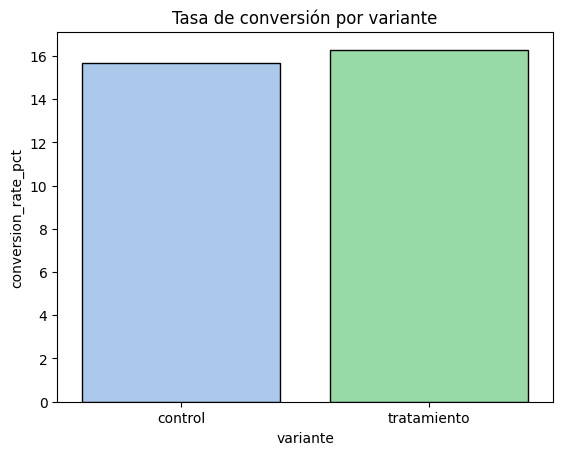

In [ ]:
# Primero revisemos los casos de exito para cada variante
conversion_variante = (
    experiment_checkout
    .groupby('variante')['convirtio']
    .agg(users="count", conversions="sum", conversion_rate="mean")
    .reset_index()
)

conversion_variante["conversion_rate_pct"] = conversion_variante["conversion_rate"] * 100
display(conversion_variante)
print()

# visualizacion
ax = sns.barplot(
    data=conversion_variante,
    x='variante',
    y='conversion_rate_pct',
    palette=['#a1c9f4', '#8de5a1'],
    edgecolor='black'
)

plt.title("Tasa de conversión por variante")


Se observa que la variante tratamiento convierte 16.29 % y control 15.69 %, diferencia de 0.60 puntos porcentuales.

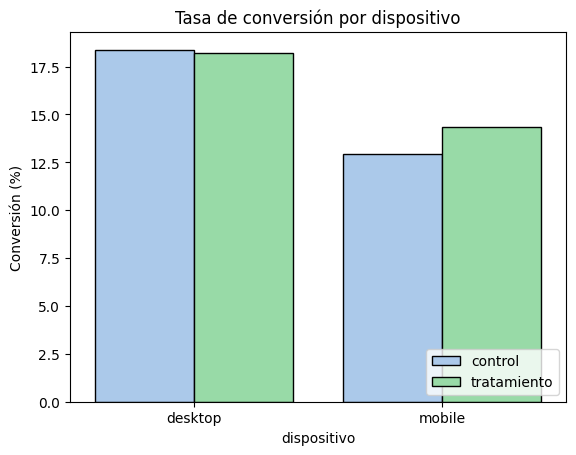

Resultados de dispositivo:


,dispositivo,variante,convirtio,conversion_rate_pct
0,desktop,control,0.183812,18.381180
1,desktop,tratamiento,0.181926,18.192581
2,mobile,control,0.129426,12.942613
3,mobile,tratamiento,0.143543,14.354258


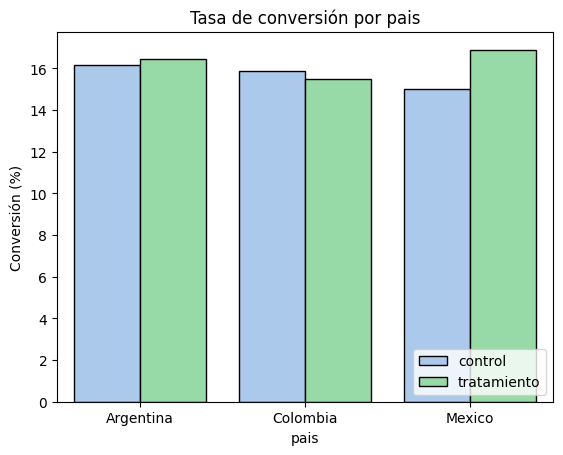

Resultados de pais:


,pais,variante,convirtio,conversion_rate_pct
0,Argentina,control,0.161836,16.183575
1,Argentina,tratamiento,0.164359,16.435882
2,Colombia,control,0.158701,15.870098
3,Colombia,tratamiento,0.154921,15.492102
4,Mexico,control,0.150268,15.026834
5,Mexico,tratamiento,0.168981,16.898148


In [ ]:
# revisemos como se comportan las conversiones por variante en 'dispositivo' y 'pais'
cols_segmento = ['dispositivo', 'pais']

resultados = {}

for col in cols_segmento:
    conversiones = (
        experiment_checkout
        .groupby([col, 'variante'])['convirtio']
        .mean()
        .reset_index()
    )

    conversiones['conversion_rate_pct'] = (
        conversiones['convirtio'] * 100
    )
    resultados[col] = conversiones

# Visualización + resultados
for col in cols_segmento:

    # Crear gráfico
    sns.barplot(
        data=resultados[col],
        x=col,
        y='conversion_rate_pct',
        hue='variante',
        palette=['#a1c9f4', '#8de5a1'],
        edgecolor='black'
    )

    plt.title(f"Tasa de conversión por {col}")
    plt.xlabel(col)
    plt.ylabel("Conversión (%)")
    plt.legend(loc='lower right')
    plt.show()

    # Mostrar resultados debajo del gráfico
    print(f"Resultados de {col}:")
    display(
        resultados[col].sort_values([col, 'variante'])
    )

Observaciones.

- Tasa de conversion por dispositivo:

En general, Desktop (control 18.381180/ tratamiento 18.192581) predomina sobre mobile.
En mobile, destaca la variante tratamiento (14.354258) sobre control (12.942613).

- Tasa de conversion por país:
Se observa mayor diferencia de conversion en Mexico.
Diferencias entre las variantes control y tratamiento:
Argentina: 0.25
Colombia: 0.37
Mexico: 1.87

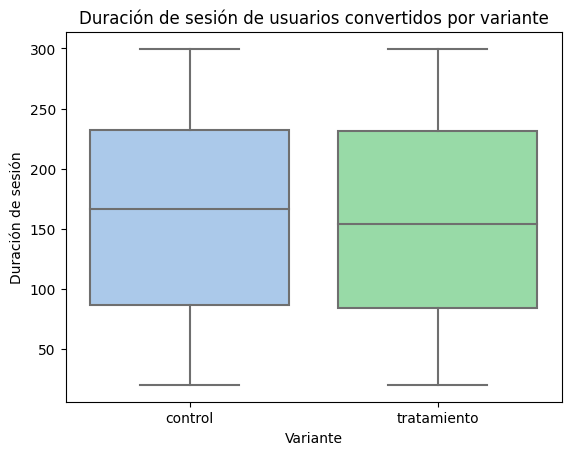

La media para duracion_sesion_control es:  162.42
La media para duracion_sesion_tratamiento es:  158.05
La diferencia es de:  4.37


In [ ]:
# visualizar si la duracion de la sesion es un factor de conversion
datos_convertidos = experiment_checkout[
    experiment_checkout['convirtio'] == 1
]

# Visualización
sns.boxplot(
    data=datos_convertidos,
    x='variante',
    y='duracion_sesion',
    palette=['#a1c9f4', '#8de5a1']
)

plt.title("Duración de sesión de usuarios convertidos por variante")
plt.xlabel("Variante")
plt.ylabel("Duración de sesión")
plt.show()

#Calcular el tiempo de duracion de sesion por variante convertido:
duracion_sesion_control = experiment_checkout[(experiment_checkout['variante'] == 'control') & (experiment_checkout['convirtio'] == 1)]['duracion_sesion']
duracion_sesion_tratamiento = experiment_checkout[(experiment_checkout['variante'] == 'tratamiento') & (experiment_checkout['convirtio'] == 1)]['duracion_sesion']

# Calcular promedios
media_duracion_sesion_control = round(duracion_sesion_control.mean(), 2)
media_duracion_sesion_tratamiento = round(duracion_sesion_tratamiento.mean(), 2)
diff= round(media_duracion_sesion_control - media_duracion_sesion_tratamiento, 2)

print('La media para duracion_sesion_control es: ', media_duracion_sesion_control)
print('La media para duracion_sesion_tratamiento es: ', media_duracion_sesion_tratamiento)
print('La diferencia es de: ', diff)


- La variante control tiene ventaja de 4.37 duracion de sesion media sobre tratamiento.

---
Hipótesis estadística: revisemos si hay diferencia estadisticamente significativa entre duracion de sesion en control y tratamiento.
   - **H₀ (Hipótesis nula):** no hay evidencia estadísticamente significativa de una diferencia en duracion de sesion entre control y tratamiento.
   - **H₁ (Hipótesis alternativa):** hay evidencia estadísticamente significativa de una diferencia en duracion de sesion entre control y tratamiento.
   
**Test estadístico:** Test Student, t-test: duracion sesion/ convirtio.
**Nivel de significancia alpha:** 0.05

In [ ]:
# Calcular el tiempo de duracion de sesion por variante convertido:
duracion_sesion_control = experiment_checkout[(experiment_checkout['variante'] == 'control') & (experiment_checkout['convirtio'] == 1)]['duracion_sesion']
duracion_sesion_tratamiento = experiment_checkout[(experiment_checkout['variante'] == 'tratamiento') & (experiment_checkout['convirtio'] == 1)]['duracion_sesion']

print("Duración de sesión - Control:")
print(duracion_sesion_control.head())

print("\nDuración de sesión - Tratamiento:")
print(duracion_sesion_tratamiento.head())
print()

# Verificar cantidad de datos que tiene cada grupo
print("Usuarios convertidos control:", len(duracion_sesion_control))
print("Usuarios convertidos tratamiento:", len(duracion_sesion_tratamiento))
print()

# Ejecutar prueba de Levene para revisar las varianzas.
l_stat, p_value_var = levene(duracion_sesion_control, duracion_sesion_tratamiento)
print(f"Estadístico de Levene: {l_stat}")
print(f"Valor p: {p_value_var}")

alpha = 0.05  # umbral de significancia
if p_value_var < alpha:
    print("Rechazamos la hipótesis nula: hay evidencia de varianzas diferentes (equal_var=False).")
else:
    print("No rechazamos la hipótesis nula: no hay evidencia de varianzas diferentes (equal_var=True).")

Duración de sesión - Control:
2     140.21
16    109.61
22    192.57
39     51.27
58    283.40
Name: duracion_sesion, dtype: float64

Duración de sesión - Tratamiento:
13     75.19
15    108.15
17    102.83
27    241.84
32     39.81
Name: duracion_sesion, dtype: float64

Usuarios convertidos control: 779
Usuarios convertidos tratamiento: 820

Estadístico de Levene: 0.23541038279679855
Valor p: 0.6276073584423275
No rechazamos la hipótesis nula: no hay evidencia de varianzas diferentes (equal_var=True).


In [ ]:
# Aplicar prueba t-test considerando varianzas iguales:
t_stat, p_value = ttest_ind(duracion_sesion_control, duracion_sesion_tratamiento, equal_var=True)

# Visualizar resultados
print(f"Estadístico : {t_stat}")
print(f"Valor p: {p_value}")

alpha = 0.05   # umbral de significancia
if p_value < alpha:
    print("Rechazamos la hipótesis nula: hay evidencia estadísticamente significativa de una diferencia en duracion de sesion entre control y tratamiento.")
else:
    print("No rechazamos la hipótesis nula: no hay evidencia estadísticamente significativa de una diferencia en duracion de sesion entre control y tratamiento.")
print()
# Calcular promedios
media_duracion_sesion_control = round(duracion_sesion_control.mean(), 2)
media_duracion_sesion_tratamiento = round(duracion_sesion_tratamiento.mean(), 2)
diff= round( media_duracion_sesion_control - media_duracion_sesion_tratamiento,2)

print('La media para duracion_sesion_control es: ', media_duracion_sesion_control)
print('La media para duracion_sesion_tratamiento es: ', media_duracion_sesion_tratamiento)
print('La diferencia es de: ', diff)

Estadístico : 1.0596284409665528
Valor p: 0.28947390328346456
No rechazamos la hipótesis nula: no hay evidencia estadísticamente significativa de una diferencia en duracion de sesion entre control y tratamiento.

La media para duracion_sesion_control es:  162.42
La media para duracion_sesion_tratamiento es:  158.05
La diferencia es de:  4.37


Decision:
- Dado que el p-value (0.2895) es mayor que el nivel de significancia de 0.05, no rechazamos la hipótesis nula. Por lo tanto, no existe evidencia estadísticamente significativa de una diferencia en la duración media de sesión entre las variantes control y tratamiento. Aunque la duración promedio fue de 162.42 en control y 158.05 en tratamiento, con una diferencia observada de 4.37 unidades de tiempo, esta diferencia no es estadísticamente significativa.

Interpretación de negocio:
- El tratamiento no muestra un efecto estadísticamente significativo sobre la duración de las sesiones. Aunque los usuarios del grupo tratamiento tuvieron una duración promedio 4.37 unidades de tiempo menor que los del grupo control, no hay evidencia suficiente para considerar esta diferencia como un efecto real del tratamiento. Por lo tanto, no sería recomendable tomar decisiones sobre el desempeño del tratamiento basándose únicamente en la duración de sesión.

---
Hipótesis estadística: revisemos si hay diferencia estadisticamente significativa entre variantes.
   - **H₀ (Hipótesis nula):** no hay evidencia estadísticamente significativa de una diferencia en la tasa de conversion entre variante control y tratamiento.
   - **H₁ (Hipótesis alternativa):** hay evidencia estadísticamente significativa de una diferencia en la tasa de conversion entre variante control y tratamiento
   
**Test estadístico:** Test de proporciones, z: variante/ convirtio.
**Nivel de significancia alpha:** 0.05

In [ ]:
# Prueba z de proporciones por variante
# Número de usuarios convertidos por variante
conversiones = experiment_checkout.groupby('variante')['convirtio'].sum()

# Total de usuarios por variante
totales = experiment_checkout.groupby('variante')['convirtio'].count()

print("Usuarios convertidos por variante:\n", conversiones)
print("\nTotal de usuarios por variante:\n", totales)

# Pasar datos a formato lista
conteos = [conversiones['control'], conversiones['tratamiento']]
num_observaciones = [totales['control'], totales['tratamiento']]

print()
# Aplicar prueba
z_stat, p_value = proportions_ztest(conteos , num_observaciones)

# Visualizar resultados
print(f"Estadístico : {z_stat}")
print(f"Valor p: {p_value}")

alpha = 0.05  # umbral de significancia
if p_value < alpha:
    print("Rechazamos la hipótesis nula: hay evidencia estadísticamente significativade una diferencia en la tasa de conversion entre variante control y tratamiento.")
else:
    print("No rechazamos la hipótesis nula: no hay evidencia estadísticamente significativa de una diferencia en la tasa de conversion entre variante control y tratamiento.")

# Obtener tasa o porcentaje de éxito por grupo
tasa_control = conteos [0] / num_observaciones [0]
tasa_tratamiento = conteos [1] / num_observaciones [1]

print(f"\nTasa de conversion variante control: {tasa_control: .2%}")
print(f"Tasa de conversion variante tratamiento: {tasa_tratamiento: .2%}")
print(f"Diferencia: {tasa_tratamiento - tasa_control:.2%}")

if tasa_control > tasa_tratamiento:
    print(f"\nLa variante control tiene una mayor tasa de conversión ({tasa_control - tasa_tratamiento:.2%}).")
elif tasa_tratamiento > tasa_control:
    print(f"\nLa variante tratamiento tiene una mayor tasa de conversión ({tasa_tratamiento - tasa_control:.2%})")
else:
    print("\nAmbas variantes tienen la misma tasa de conversión.")

Usuarios convertidos por variante:
 variante
control        779
tratamiento    820
Name: convirtio, dtype: int64

Total de usuarios por variante:
 variante
control        4965
tratamiento    5035
Name: convirtio, dtype: int64

Estadístico : -0.8132782986429474
Valor p: 0.41605851639119995
No rechazamos la hipótesis nula: no hay evidencia estadísticamente significativa de una diferencia en la tasa de conversion entre variante control y tratamiento.

Tasa de conversion variante control:  15.69%
Tasa de conversion variante tratamiento:  16.29%
Diferencia: 0.60%

La variante tratamiento tiene una mayor tasa de conversión (0.60%)


Decision:
- El z-test no encontró una diferencia estadísticamente significativa en la tasa de conversión entre las variantes control y tratamiento (z = -0.813, p = 0.416). Dado que el p-value es mayor que el nivel de significancia de 0.05, no rechazamos la hipótesis nula. La tasa de conversión fue de 15.69 % para el grupo control y de 16.29 % para el grupo tratamiento, lo que representa una diferencia observada de 0.60 puntos porcentuales a favor del tratamiento. Sin embargo, esta diferencia no es estadísticamente significativa, por lo que no hay evidencia suficiente para concluir que el tratamiento genere una mejora real en la tasa de conversión.

Interpretación de negocio:
- El tratamiento no demuestra una mejora estadísticamente significativa en la conversión. Aunque presenta una conversión ligeramente superior (16.29% frente a 15.69%), con estos resultados no hay suficiente evidencia para afirmar que el tratamiento sea mejor que el control.

---
Hipótesis estadística: revisemos si hay diferencia estadisticamente significativa entre dispositivos.
   - **H₀ (Hipótesis nula):** no hay evidencia estadísticamente significativa de una diferencia en la tasa de conversion entre mobile y desktop.
   - **H₁ (Hipótesis alternativa):** hay evidencia estadísticamente significativa de una diferencia en la tasa de conversion entre mobile y desktop.
   
**Test estadístico:** Test de proporciones, z: dispositivo/ convirtio.
**Nivel de significancia alpha:** 0.05

In [ ]:
# Prueba z de proporciones por dispositivo
# Número de usuarios convertidos por dispositivo
conversiones = experiment_checkout.groupby('dispositivo')['convirtio'].sum()

# Total de usuarios por dispositivo
totales = experiment_checkout.groupby('dispositivo')['convirtio'].count()

print("Usuarios convertidos por dispositivo:\n", conversiones)
print("\nTotal de usuarios por dispositivo:\n", totales)

# Pasar datos a formato lista
conteos = [conversiones['mobile'], conversiones['desktop']]
num_observaciones = [totales['mobile'], totales['desktop']]

# Aplicar prueba
z_stat, p_value = proportions_ztest(conteos , num_observaciones)
print()
# Visualizar resultados
print(f"Estadístico : {z_stat}")
print(f"Valor p: {p_value}")

alpha = 0.05  # umbral de significancia
if p_value < alpha:
    print("Rechazamos la hipótesis nula: hay evidencia estadísticamente significativa de una diferencia en la tasa de conversion entre mobile y desktop.")
else:
    print("No rechazamos la hipótesis nula: no hay evidencia estadísticamente significativa de una diferencia en la tasa de conversion entre mobile y desktop.")

# Obtener tasa o porcentaje de éxito por grupo
tasa_mobile = conteos [0] / num_observaciones [0]
tasa_desktop = conteos [1] / num_observaciones [1]

print(f"\nTasa de conversion mobile: {tasa_mobile: .2%}")
print(f"Tasa de conversion desktop: {tasa_desktop: .2%}")
print(f"Diferencia: {tasa_desktop - tasa_mobile:.2%}")

if tasa_mobile > tasa_desktop:
    print(f"\nDispositivo mobile tiene una mayor tasa de conversión ({tasa_mobile - tasa_desktop:.2%}).")
elif tasa_desktop > tasa_mobile:
    print(f"\nDispositivo desktop tiene una mayor tasa de conversión ({tasa_desktop - tasa_mobile:.2%})")
else:
    print("\nAmbos dispositivos tienen la misma tasa de conversión.")

Usuarios convertidos por dispositivo:
 dispositivo
desktop    922
mobile     677
Name: convirtio, dtype: int64

Total de usuarios por dispositivo:
 dispositivo
desktop    5042
mobile     4958
Name: convirtio, dtype: int64

Estadístico : -6.318367655127404
Valor p: 2.6434053323190774e-10
Rechazamos la hipótesis nula: hay evidencia estadísticamente significativa de una diferencia en la tasa de conversion entre mobile y desktop.

Tasa de conversion mobile:  13.65%
Tasa de conversion desktop:  18.29%
Diferencia: 4.63%

Dispositivo desktop tiene una mayor tasa de conversión (4.63%)


Decision:
- El z-test mostró una diferencia estadísticamente significativa en la tasa de conversión entre usuarios mobile y desktop (z = -6.318, p < 0.05). Dado que el p-value es menor que el nivel de significancia de 0.05, rechazamos la hipótesis nula. La tasa de conversión fue de 13.65 % en mobile y de 18.29 % en desktop, lo que representa una diferencia de aproximadamente 4.63 puntos porcentuales a favor de desktop. Por lo tanto, existe evidencia estadísticamente significativa de que la tasa de conversión difiere entre ambos dispositivos.

Interpretación de negocio:
- Los usuarios en desktop presentan una tasa de conversión significativamente mayor que los usuarios en mobile (18.29 % vs. 13.65 %). Esto sugiere una oportunidad de negocio para investigar y mejorar la experiencia de conversión en dispositivos móviles, ya que existe una brecha de aproximadamente 4.63 puntos porcentuales respecto a desktop.

Acción recomendada: analizar el funnel mobile para identificar posibles problemas de usabilidad, velocidad, diseño o proceso de compra que puedan estar afectando la conversión.

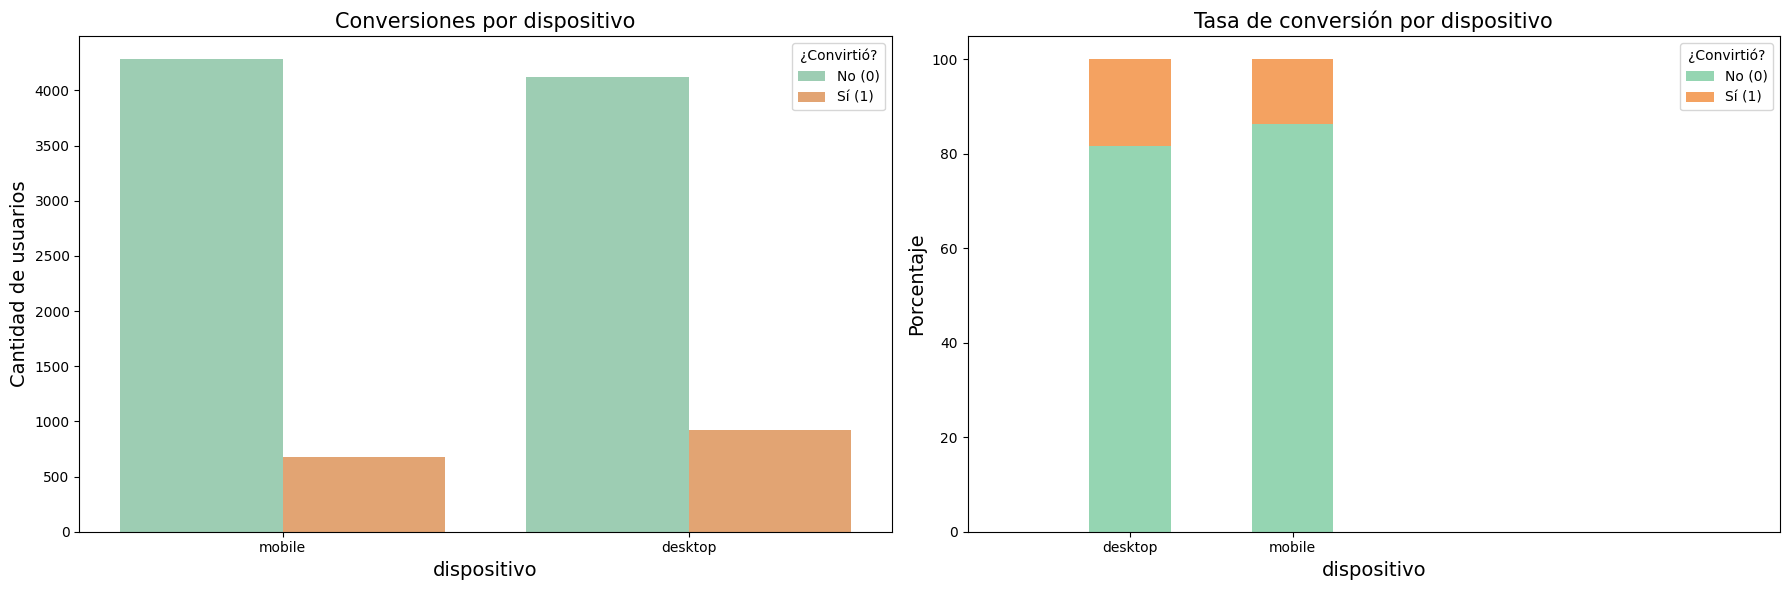

In [ ]:
# Relacion entre dispositivo y convesion
#Tabla de contingencia normalizada
tabla_dispositivo = pd.crosstab(experiment_checkout['dispositivo'], experiment_checkout['convirtio'], normalize='index') * 100
tabla_dispositivo

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
sns.countplot(data=experiment_checkout, x='dispositivo', hue='convirtio', palette=["#95D5B2", "#F4A261"], ax=axes[0])

axes[0].set_title('Conversiones por dispositivo', fontsize=15)
axes[0].set_xlabel('dispositivo', fontsize=14)
axes[0].set_ylabel('Cantidad de usuarios', fontsize=14)
axes[0].legend(title='¿Convirtió?', labels=['No (0)', 'Sí (1)'])

tabla_dispositivo.plot(kind='bar', stacked=True, color=["#95D5B2", "#F4A261"], ax=axes[1])

axes[1].set_title('Tasa de conversión por dispositivo', fontsize=15)
axes[1].set_xlabel('dispositivo', fontsize=14)
axes[1].set_ylabel('Porcentaje', fontsize=14)
axes[1].set_xlim(-1, 4)
axes[1].legend(title='¿Convirtió?', labels=['No (0)', 'Sí (1)'], loc='upper right')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

OBSERVACIONES: el gráfico de la izquierda muestra la cantidad de usuarios que se convirtieron y no convirtieron según el dispositivo. Se observa que 'Desktop' concentra mejor volumen que 'Mobile'. El gráfico de la derecha muestra la tasa de conversión independientemente del volumen total y en efecto, se aprecia la diferencia de tasa por conversion a favor de 'Desktop'.

---
Hipótesis estadística: revisemos si hay diferencia estadisticamente significativa entre paises.
   - **H₀ (Hipótesis nula):** "no existe evidencia estadísticamente significativa de una asociación entre el país y la conversión."
   - **H₁ (Hipótesis alternativa):** "hay evidencia estadísticamente significativa de una asociación entre el país y la conversión."
   
**Test estadístico:** Test chi2: paises/ convirtio.
**Nivel de significancia alpha:** 0.05

In [ ]:

tabla = pd.crosstab(experiment_checkout['pais'], experiment_checkout['convirtio'])
print(tabla)
print()

# Aplicar prueba
chi2_stat, p_value, dof, expected = chi2_contingency(tabla)

print(f"Estadístico chi-cuadrado: {chi2_stat}")
print(f"Valor P: {p_value}")
print(f"Grados de libertad: {dof}")
print("\nFrecuencias esperadas:")
print(expected)

expected_df = pd.DataFrame(expected, index=tabla.index, columns=tabla.columns )
expected_df
print()
alpha = 0.05  # umbral de significancia

if p_value < alpha:
    print("Rechazamos la hipótesis nula: existe evidencia estadísticamente significativa de una asociación entre el país y la conversión.")
else:
    print("No rechazamos la hipótesis nula: no existe evidencia estadísticamente significativa de una asociación entre el país y la conversión.")
print()

# Tabla de contingencia normalizada
tabla_pais = pd.crosstab(experiment_checkout['pais'], experiment_checkout['convirtio'], normalize='index') * 100
tabla_pais

convirtio     0    1
pais                
Argentina  2776  541
Colombia   2764  514
Mexico     2861  544

Estadístico chi-cuadrado: 0.4872472982531369
Valor P: 0.7837825560118881
Grados de libertad: 2

Frecuencias esperadas:
[[2786.6117  530.3883]
 [2753.8478  524.1522]
 [2860.5405  544.4595]]

No rechazamos la hipótesis nula: no existe evidencia estadísticamente significativa de una asociación entre el país y la conversión.



convirtio,0,1
pais,,
Argentina,83.690081,16.309919
Colombia,84.319707,15.680293
Mexico,84.023495,15.976505


Decision:
- Dado que el p-value (0.7838) es mayor que el nivel de significancia de 0.05, no rechazamos la hipótesis nula. Por lo tanto, no existe evidencia estadísticamente significativa de una asociación entre el país y la conversión. Aunque las tasas de conversión presentan pequeñas diferencias entre Argentina (16.31%), Colombia (15.68%) y México (15.98%), estas diferencias no son estadísticamente significativas.

Interpretacion del negocio:
- El país del usuario no parece estar relacionado significativamente con la conversión. Las tasas son muy similares entre Argentina, Colombia y México, por lo que no hay evidencia suficiente para justificar estrategias de conversión diferenciadas únicamente por país.

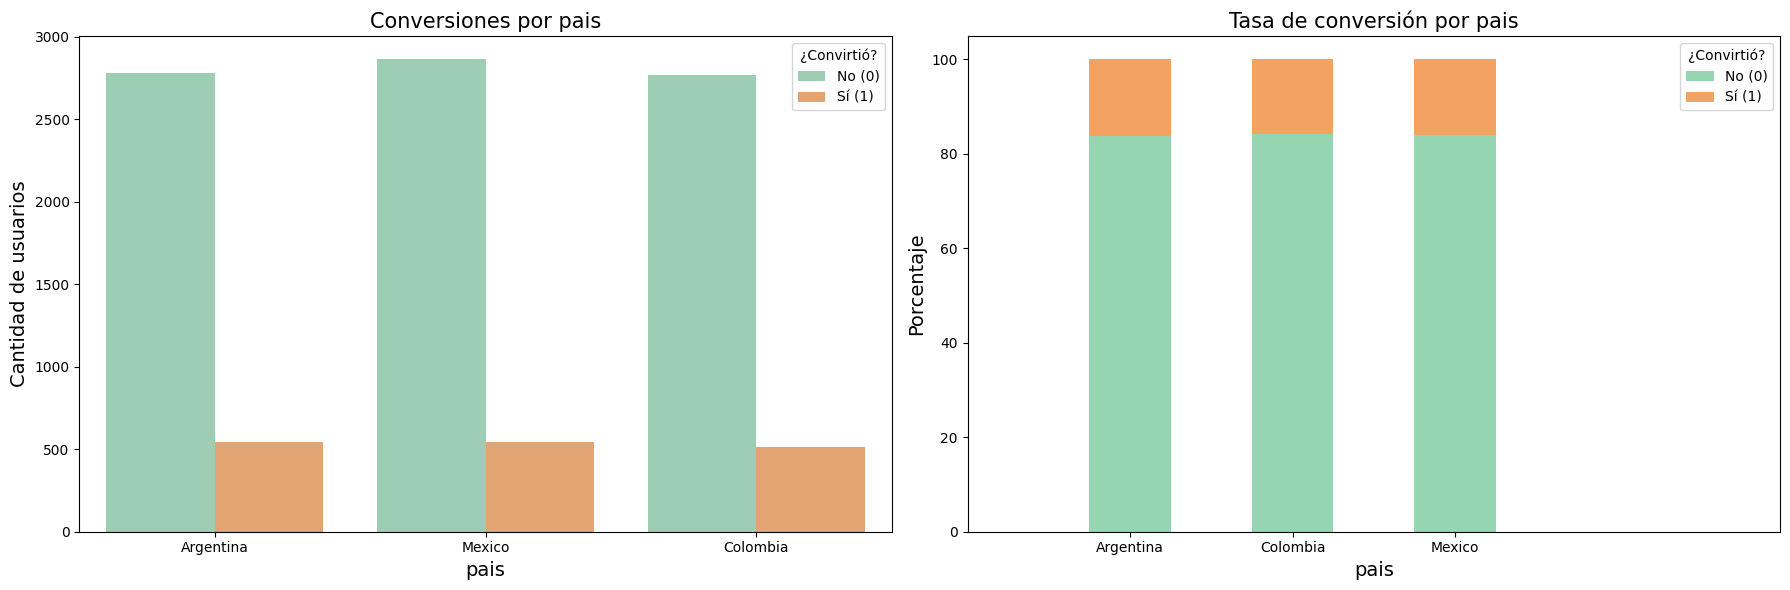

In [ ]:
# Relación entre pais y la conversión

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
sns.countplot(data=experiment_checkout, x='pais', hue='convirtio', palette=["#95D5B2", "#F4A261"], ax=axes[0])

axes[0].set_title('Conversiones por pais', fontsize=15)
axes[0].set_xlabel('pais', fontsize=14)
axes[0].set_ylabel('Cantidad de usuarios', fontsize=14)
axes[0].legend(title='¿Convirtió?', labels=['No (0)', 'Sí (1)'])

tabla_pais.plot(kind='bar', stacked=True, color=["#95D5B2", "#F4A261"], ax=axes[1])

axes[1].set_title('Tasa de conversión por pais', fontsize=15)
axes[1].set_xlabel('pais', fontsize=14)
axes[1].set_ylabel('Porcentaje', fontsize=14)
axes[1].set_xlim(-1, 4)
axes[1].legend(title='¿Convirtió?', labels=['No (0)', 'Sí (1)'], loc='upper right')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()


OBSERVACIONES: el gráfico de la izquierda muestra la cantidad de usuarios que se convirtieron y no convirtieron según el pais. A simple vista, se observa un comportamiento homogeneo en los 3 paises. El gráfico de la derecha muestra la tasa de conversión independientemente del volumen total y ninguno destaca considerablemente.

---

## 🔹 Paso 6: Comunicar los resultados (Dashboard en BI)

🎯 **Objetivo**:  
Crear un dashboard que muestre de manera clara y visual los resultados del análisis de ventas, costos, marketing y conversión.

Se usarán los CSVs limpios del Paso 1:

- `orders_clean.csv`  
- `catalog_clean.csv`  
- `marketing_clean.csv`

---

1️⃣ Preparación de los datos
1. Cargar los CSVs en Power BI o Tableau.
2. Revisar relaciones:
   - `orders.nombre_producto` → `catalog.nombre_producto`
   - `orders.fecha_pedido` → tabla de fechas (crear calendario para análisis temporal)
   - `orders.fecha_pedido` → `dim_fecha.date`
3. Crear columnas calculadas necesarias
4. Crear tabla de fechas para poder calcular comparaciones YTD, YoY o períodos anteriores (`Previous Year`, `Previous Month`).

---

2️⃣ Dashboard 1: Overview Ejecutivo
**KPIs principales a mostrar:**
- Revenue total
- Profit total
- Gasto total en marketing
- Ticket promedio
- Cantidad promedio de productos por orden

**Visualizaciones sugeridas:**
- Tarjetas KPI para revenue, profit y gasto marketing
- Gráfico de líneas: evolución mensual de revenue o profit
- Gráfico de líneas YTD
- Gráfico de barras: revenue y profit por producto o categoría

---

 3️⃣ Dashboard 2: Detalle / Drill-through  
**Objetivo:** Permitir explorar los datos desde el KPI general hasta cada orden o producto.

**Visualizaciones sugeridas:**
- Tabla detallada de órdenes con:
  - producto, cantidad, revenue, cost, profit
  - color condicional (profit negativo en rojo, positivo en verde)
- Gráfico de barras por producto con medida `cantidad vendida`
- Drill-through: seleccionar un producto y ver todos los pedidos relacionados
- Filtros por fecha, categoría de producto, etc

---